In [104]:
import pandas as pd  
  
# Load the dataset  
df = pd.read_csv('./data/resale_transactions_categorised.csv')

In [105]:
# Allow all columns to render so VS Code's horizontal scrollbar activates
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

In [106]:
df.head()

,id,month,flat_type,block,street_name,storey_range,floor_area_sqm,lease_commence_date,remaining_lease,town_id,flatm_id,town_name,flatm_name,price_category
0,1,2018-05,5 ROOM,118,PASIR RIS ST 11,07 TO 09,123.0,1989,70 years 03 months,17,5,PASIR RIS,Improved,Above Median
1,2,2016-10,4 ROOM,101,RIVERVALE WALK,01 TO 03,100.0,1999,81,21,8,SENGKANG,Model A,Below Median
2,3,2018-10,5 ROOM,688A,CHOA CHU KANG DR,19 TO 21,110.0,2002,82 years 06 months,9,5,CHOA CHU KANG,Improved,Below Median
3,4,2015-12,4 ROOM,130,LOR AH SOO,13 TO 15,103.0,1984,67,12,8,HOUGANG,Model A,Above Median
4,5,2017-09,5 ROOM,533,SERANGOON NTH AVE 4,07 TO 09,122.0,1992,74 years 02 months,22,5,SERANGOON,Improved,Above Median


In [107]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 88688 entries, 0 to 88687
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   88688 non-null  int64  
 1   month                88688 non-null  str    
 2   flat_type            88688 non-null  str    
 3   block                88688 non-null  str    
 4   street_name          88688 non-null  str    
 5   storey_range         88688 non-null  str    
 6   floor_area_sqm       88688 non-null  float64
 7   lease_commence_date  88688 non-null  int64  
 8   remaining_lease      88688 non-null  str    
 9   town_id              88688 non-null  int64  
 10  flatm_id             88688 non-null  int64  
 11  town_name            87905 non-null  str    
 12  flatm_name           88174 non-null  str    
 13  price_category       88688 non-null  str    
dtypes: float64(1), int64(4), str(9)
memory usage: 9.5 MB


In [108]:
df.isnull().sum()

id                       0
month                    0
flat_type                0
block                    0
street_name              0
storey_range             0
floor_area_sqm           0
lease_commence_date      0
remaining_lease          0
town_id                  0
flatm_id                 0
town_name              783
flatm_name             514
price_category           0
dtype: int64

In [109]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,88688.0,42233.303739,24376.312037,1.0,21136.75,42228.5,63339.25,84465.0
floor_area_sqm,88688.0,97.520444,24.197379,31.0,76.00,96.0,112.00,280.0
lease_commence_date,88688.0,1570.225352,1226.315949,-2016.0,1980.00,1988.0,2000.00,2016.0
town_id,88688.0,14.631337,8.032285,1.0,8.00,15.0,22.00,26.0
flatm_id,88688.0,8.889185,3.906898,1.0,5.00,8.0,12.00,21.0


In [110]:
df.duplicated().sum()

np.int64(4223)

In [111]:
df[df.duplicated(keep=False)].sort_values(by=list(df.columns))

,id,month,flat_type,block,street_name,storey_range,floor_area_sqm,lease_commence_date,remaining_lease,town_id,flatm_id,town_name,flatm_name,price_category
103,104,2016-09,3 ROOM,201E,TAMPINES ST 23,04 TO 06,68.0,-1987,70,23,12,TAMPINES,New Generation,Below Median
88570,104,2016-09,3 ROOM,201E,TAMPINES ST 23,04 TO 06,68.0,-1987,70,23,12,TAMPINES,New Generation,Below Median
106,107,2015-08,4 ROOM,146,SERANGOON NTH AVE 1,13 TO 15,83.0,-1987,70,22,17,SERANGOON,Simplified,Below Median
88156,107,2015-08,4 ROOM,146,SERANGOON NTH AVE 1,13 TO 15,83.0,-1987,70,22,17,SERANGOON,Simplified,Below Median
114,115,2017-03,4 ROOM,274D,PUNGGOL PL,16 TO 18,93.0,2013,95 years 04 months,18,13,PUNGGOL,Premium Apartment,Above Median
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87372,84427,2019-01,5 ROOM,348D,YISHUN AVE 11,13 TO 15,112.0,2013,93 years 09 months,26,4,YISHUN,DBSS,Above Median
84428,84429,2018-10,4 ROOM,838,HOUGANG CTRL,04 TO 06,100.0,-1997,77 years 05 months,12,8,HOUGANG,Model A,Above Median
85835,84429,2018-10,4 ROOM,838,HOUGANG CTRL,04 TO 06,100.0,-1997,77 years 05 months,12,8,HOUGANG,Model A,Above Median
84461,84462,2015-06,5 ROOM,596A,ANG MO KIO ST 52,07 TO 09,110.0,2002,86,1,5,ANG MO KIO,Improved,Above Median


In [112]:
df.drop_duplicates(inplace=True)

C:\Users\ksgsu\AppData\Local\Temp\ipykernel_5180\3006716147.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


In [113]:
import seaborn as sns
import matplotlib.pyplot as plt

C:\Users\ksgsu\AppData\Local\Temp\ipykernel_5180\1792947088.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  count_plot = sns.countplot(x='price_category', data=df, palette='pastel')


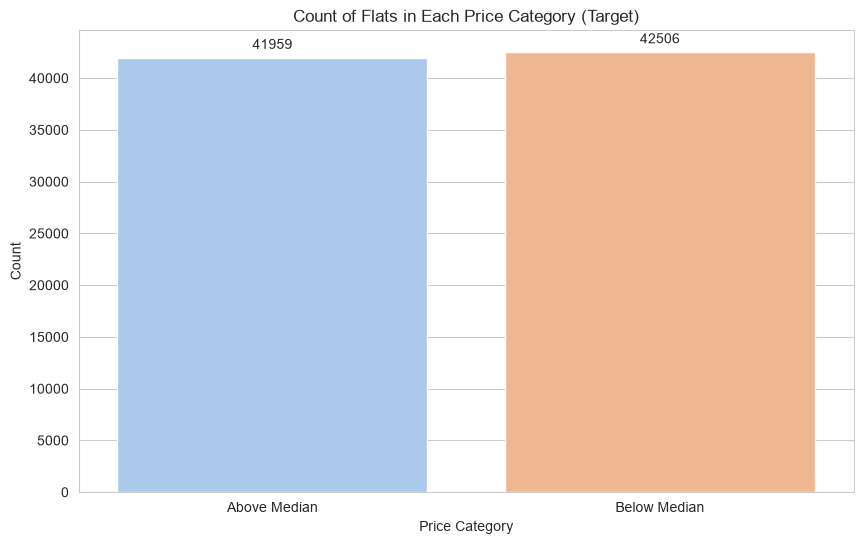

In [114]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for price category with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='price_category', data=df, palette='pastel')
plt.title('Count of Flats in Each Price Category (Target)')
plt.xlabel('Price Category')
plt.ylabel('Count')
#plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

In [115]:
# Encode the target column
df['price_category'] = df['price_category'].map({'Above Median': 1, 'Below Median': 0})

# Check the distribution of the target column
df['price_category'].value_counts()

price_category
0    42506
1    41959
Name: count, dtype: int64

In [116]:
# Replace 'FOUR ROOM' with '4 ROOM' in the 'flat_type' column
df['flat_type'] = df['flat_type'].replace('FOUR ROOM', '4 ROOM')
  
# Verify the changes
print(df['flat_type'].value_counts())

flat_type
4 ROOM              34828
3 ROOM              21490
5 ROOM              20449
EXECUTIVE            6685
2 ROOM                944
1 ROOM                 38
MULTI-GENERATION       31
Name: count, dtype: int64


In [117]:
df.head()

,id,month,flat_type,block,street_name,storey_range,floor_area_sqm,lease_commence_date,remaining_lease,town_id,flatm_id,town_name,flatm_name,price_category
0,1,2018-05,5 ROOM,118,PASIR RIS ST 11,07 TO 09,123.0,1989,70 years 03 months,17,5,PASIR RIS,Improved,1
1,2,2016-10,4 ROOM,101,RIVERVALE WALK,01 TO 03,100.0,1999,81,21,8,SENGKANG,Model A,0
2,3,2018-10,5 ROOM,688A,CHOA CHU KANG DR,19 TO 21,110.0,2002,82 years 06 months,9,5,CHOA CHU KANG,Improved,0
3,4,2015-12,4 ROOM,130,LOR AH SOO,13 TO 15,103.0,1984,67,12,8,HOUGANG,Model A,1
4,5,2017-09,5 ROOM,533,SERANGOON NTH AVE 4,07 TO 09,122.0,1992,74 years 02 months,22,5,SERANGOON,Improved,1


In [118]:
# Function to convert storey_range to ordinal scale by taking the average of the range
def convert_storey_range(storey_range: str) -> float:
    """
    Converts a storey range string into its average numerical value.
    
    The function takes a storey range in the format 'XX TO YY', splits it into two parts,
    converts these parts to integers, and returns the average of these integers.
    
    Args:
        storey_range (str): A string representing a range of storeys, in the format 'XX TO YY'.
        
    Returns:
        float: The average value of the two storeys in the range.
        
    Example:
        convert_storey_range('07 TO 09') -> 8.0
    """
    range_values = storey_range.split(' TO ')
    return (int(range_values[0]) + int(range_values[1])) / 2

# Use the .apply() method to convert the 'storey_range' column with the function
df['storey_range'] = df['storey_range'].apply(convert_storey_range)

In [119]:
df.head()

,id,month,flat_type,block,street_name,storey_range,floor_area_sqm,lease_commence_date,remaining_lease,town_id,flatm_id,town_name,flatm_name,price_category
0,1,2018-05,5 ROOM,118,PASIR RIS ST 11,8.0,123.0,1989,70 years 03 months,17,5,PASIR RIS,Improved,1
1,2,2016-10,4 ROOM,101,RIVERVALE WALK,2.0,100.0,1999,81,21,8,SENGKANG,Model A,0
2,3,2018-10,5 ROOM,688A,CHOA CHU KANG DR,20.0,110.0,2002,82 years 06 months,9,5,CHOA CHU KANG,Improved,0
3,4,2015-12,4 ROOM,130,LOR AH SOO,14.0,103.0,1984,67,12,8,HOUGANG,Model A,1
4,5,2017-09,5 ROOM,533,SERANGOON NTH AVE 4,8.0,122.0,1992,74 years 02 months,22,5,SERANGOON,Improved,1


In [120]:
def fill_missing_names(df: pd.DataFrame, id_column: str, name_column: str) -> pd.DataFrame:
    """
    Fills missing values in the 'name_column' using the 'id_column'.

    Args:
        df (pd.DataFrame): The DataFrame containing the columns to be filled.
        id_column (str): The name of the column containing the IDs.
        name_column (str): The name of the column containing the names to be filled.

    Returns:
        pd.DataFrame: The DataFrame with missing values in 'name_column' filled.
    """
    # Identify missing values in the 'name_column'
    missing_names = df[name_column].isna()

    # Create a dictionary mapping 'id_column' to 'name_column'
    name_mapping = df[[id_column, name_column]].dropna().drop_duplicates().set_index(id_column)[name_column].to_dict()

    # Fill missing 'name_column' using the mapping
    df.loc[missing_names, name_column] = df.loc[missing_names, id_column].map(name_mapping)

    return df

In [121]:
# Fill missing values in 'town_name' column
df = fill_missing_names(df=df, id_column='town_id', name_column='town_name')

# Fill missing values in 'flatm_name' column
df = fill_missing_names(df=df, id_column='flatm_id', name_column='flatm_name')

In [122]:
df.head()

,id,month,flat_type,block,street_name,storey_range,floor_area_sqm,lease_commence_date,remaining_lease,town_id,flatm_id,town_name,flatm_name,price_category
0,1,2018-05,5 ROOM,118,PASIR RIS ST 11,8.0,123.0,1989,70 years 03 months,17,5,PASIR RIS,Improved,1
1,2,2016-10,4 ROOM,101,RIVERVALE WALK,2.0,100.0,1999,81,21,8,SENGKANG,Model A,0
2,3,2018-10,5 ROOM,688A,CHOA CHU KANG DR,20.0,110.0,2002,82 years 06 months,9,5,CHOA CHU KANG,Improved,0
3,4,2015-12,4 ROOM,130,LOR AH SOO,14.0,103.0,1984,67,12,8,HOUGANG,Model A,1
4,5,2017-09,5 ROOM,533,SERANGOON NTH AVE 4,8.0,122.0,1992,74 years 02 months,22,5,SERANGOON,Improved,1


In [123]:
# Drop irrelevant features
df = df.drop(columns=['id', 'town_id', 'flatm_id'])

In [124]:
# Convert 'month' column to datetime
df['year_month'] = pd.to_datetime(df['month'], format='%Y-%m')

# Extract year and month from the datetime object
df['year'] = df['year_month'].dt.year
df['month'] = df['year_month'].dt.month

df.head()

,month,flat_type,block,street_name,storey_range,floor_area_sqm,lease_commence_date,remaining_lease,town_name,flatm_name,price_category,year_month,year
0,5,5 ROOM,118,PASIR RIS ST 11,8.0,123.0,1989,70 years 03 months,PASIR RIS,Improved,1,2018-05-01,2018
1,10,4 ROOM,101,RIVERVALE WALK,2.0,100.0,1999,81,SENGKANG,Model A,0,2016-10-01,2016
2,10,5 ROOM,688A,CHOA CHU KANG DR,20.0,110.0,2002,82 years 06 months,CHOA CHU KANG,Improved,0,2018-10-01,2018
3,12,4 ROOM,130,LOR AH SOO,14.0,103.0,1984,67,HOUGANG,Model A,1,2015-12-01,2015
4,9,5 ROOM,533,SERANGOON NTH AVE 4,8.0,122.0,1992,74 years 02 months,SERANGOON,Improved,1,2017-09-01,2017


In [125]:
# drop year_month
df = df.drop(columns=['year_month'])

In [126]:
df['remaining_lease'].unique()

<StringArray>
['70 years 03 months',                 '81', '82 years 06 months',
                 '67', '74 years 02 months', '61 years 04 months',
  '74 years 01 month', '63 years 08 months',           '66 years',
                 '85',
 ...
 '53 years 08 months',                 '97',           '88 years',
 '96 years 03 months', '96 years 04 months',                 '48',
 '96 years 07 months', '96 years 08 months',  '95 years 0 months',
  '66 years 0 months']
Length: 654, dtype: str

In [127]:
import re

def extract_lease_info(lease_str: str) -> int:
    """
    Convert lease information from a string format to total months.

    This function takes a string representing the remaining lease period, which
    may include years and months in various formats (e.g., "70 years 3 months",
    "85 years", "67"), and converts it to the total number of months.

    Args:
        lease_str (str): The remaining lease period as a string.

    Returns:
        int: The total number of months, or None if the input is NaN.
    """

    if pd.isna(lease_str):
        return None
    
    # Regular expression to extract years and months
    years_match = re.search(r'(\d+)\s*years?', lease_str)
    months_match = re.search(r'(\d+)\s*months?', lease_str)
    number_match = re.match(r'^\d+$', lease_str.strip())
    
    if years_match:
        years = int(years_match.group(1))
    elif number_match:  # If only a number is present, assume it's in years
        years = int(number_match.group(0))
    else:
        years = 0
        
    months = int(months_match.group(1)) if months_match else 0
    
    # Convert the total lease period to months
    total_months = years * 12 + months
    return total_months

In [128]:
# Extract lease information  
df['remaining_lease_months'] = df['remaining_lease'].apply(extract_lease_info) 
# Display a random sample of the data to check the transformation
df[['remaining_lease', 'remaining_lease_months']].sample(5)

,remaining_lease,remaining_lease_months
1863,87,1044
81577,56 years 06 months,678
5098,63,756
44635,74 years 10 months,898
15397,88,1056


In [129]:
# Drop the 'remaining_lease' column
df = df.drop(columns=['remaining_lease'])

In [130]:
# Drop the 'block' and 'street_name' columns
df = df.drop(columns=['block', 'street_name'])

In [131]:
df.head()

,month,flat_type,storey_range,floor_area_sqm,lease_commence_date,town_name,flatm_name,price_category,year,remaining_lease_months
0,5,5 ROOM,8.0,123.0,1989,PASIR RIS,Improved,1,2018,843
1,10,4 ROOM,2.0,100.0,1999,SENGKANG,Model A,0,2016,972
2,10,5 ROOM,20.0,110.0,2002,CHOA CHU KANG,Improved,0,2018,990
3,12,4 ROOM,14.0,103.0,1984,HOUGANG,Model A,1,2015,804
4,9,5 ROOM,8.0,122.0,1992,SERANGOON,Improved,1,2017,890


In [132]:
from sklearn.model_selection import train_test_split

# Separate the data into features and target
X = df.drop(columns='price_category')
y = df['price_category']

# Split the data into training (80%) and test-validation (20%) sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Split the test-validation set (20%) into validation (10%) and test (10%) sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [133]:
# Show X - Note the uppercase
X

,month,flat_type,storey_range,floor_area_sqm,lease_commence_date,town_name,flatm_name,year,remaining_lease_months
0,5,5 ROOM,8.0,123.0,1989,PASIR RIS,Improved,2018,843
1,10,4 ROOM,2.0,100.0,1999,SENGKANG,Model A,2016,972
2,10,5 ROOM,20.0,110.0,2002,CHOA CHU KANG,Improved,2018,990
3,12,4 ROOM,14.0,103.0,1984,HOUGANG,Model A,2015,804
4,9,5 ROOM,8.0,122.0,1992,SERANGOON,Improved,2017,890
...,...,...,...,...,...,...,...,...,...
84460,9,5 ROOM,11.0,111.0,2001,SEMBAWANG,Improved,2015,1020
84461,6,5 ROOM,8.0,110.0,2002,ANG MO KIO,Improved,2015,1032
84462,9,5 ROOM,2.0,110.0,2003,HOUGANG,Improved,2017,1018
84463,4,4 ROOM,2.0,91.0,1984,ANG MO KIO,New Generation,2016,792


In [134]:
# Show y - Note the lowercase
y

0        1
1        0
2        0
3        1
4        1
        ..
84460    1
84461    1
84462    0
84463    0
84464    1
Name: price_category, Length: 84465, dtype: int64

In [136]:
from sklearn.model_selection import train_test_split

# Split the data into training (80%) and test-validation (20%) sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42)

# Split the test-validation set (20%) into validation (10%) and test (10%) sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

In [137]:
# Display the shapes of the splits to verify
print("Training set shape:", X_train.shape, y_train.shape)
print("Validation set shape:", X_val.shape, y_val.shape)
print("Test set shape:", X_test.shape, y_test.shape)

Training set shape: (67572, 9) (67572,)
Validation set shape: (8446, 9) (8446,)
Test set shape: (8447, 9) (8447,)


In [138]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Define numerical features to be standardized
numerical_features = ['floor_area_sqm', 'remaining_lease_months', 'lease_commence_date', 'year']

# Create a numerical transformer pipeline
numerical_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

In [139]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# Define nomial features to be one-hot encoded
nominal_features = ['month', 'town_name', 'flatm_name']

# Define ordinal features to be ordinally encoded
ordinal_features = ['flat_type']

# Define the ordinal categories for flat_type
flat_type_categories = ['1 ROOM', '2 ROOM', '3 ROOM', '4 ROOM', '5 ROOM', 'MULTI-GENERATION', 'EXECUTIVE']

# Define passthrough features that will not be transformed
passthrough_features = ['storey_range']

# Create a nominal transformer pipeline
nominal_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Create an ordinal transformer pipeline
ordinal_transformer = Pipeline(steps=[
    ('ordinal', OrdinalEncoder(categories=[flat_type_categories], handle_unknown='use_encoded_value', unknown_value=-1))  
])

In [140]:
from sklearn.compose import ColumnTransformer

# Combine transformers into a single ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('nom', nominal_transformer, nominal_features),
        ('ord', ordinal_transformer, ordinal_features),
        ('pass', 'passthrough', passthrough_features) # Pass through the storey_range feature without transformation
    ],
    remainder='passthrough',
    n_jobs=-1
    )

In [141]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('nom', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",-1
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feat

In [142]:
# Import the necessary library
from sklearn.linear_model import LogisticRegression

# Create the pipeline with a logistic regression model
logreg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),  # Use the preprocessor pipeline defined earlier
    ('classifier', LogisticRegression(max_iter=1000))
])

# Fit the pipeline to the training data
logreg_pipeline.fit(X_train, y_train)

# Predict on the validation set
y_val_pred = logreg_pipeline.predict(X_val)

In [143]:
logreg_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['month','flat_type','storey_range',...,'flatm_name','year', 'remaining_lease_months']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('nom', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [144]:
y_val_pred

array([0, 1, 0, ..., 1, 0, 1], shape=(8446,))

In [145]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate the classification metrics for Logistic Regression
logreg_val_accuracy = accuracy_score(y_val, y_val_pred)

# Display the metrics for Logistic Regression
print("Logistic Regression Metrics:")
print(f'LogReg Validation Accuracy: {logreg_val_accuracy:.5f}')

Logistic Regression Metrics:
LogReg Validation Accuracy: 0.89119


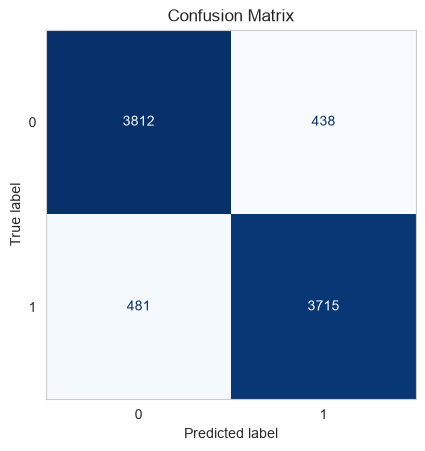

In [146]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cm = confusion_matrix(y_val, y_val_pred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
fig, ax = plt.subplots()
disp.plot(cmap=plt.cm.Blues, ax=ax, colorbar=False)
plt.title("Confusion Matrix")
plt.grid(False)
plt.show()

In [147]:
# Calculate the classification metrics for Logistic Regression
logreg_val_precision = precision_score(y_val, y_val_pred)
logreg_val_recall = recall_score(y_val, y_val_pred)
logreg_val_f1 = f1_score(y_val, y_val_pred)

# Display the metrics for Logistic Regression
print("Logistic Regression Metrics:")
print(f'LogReg Validation Precision: {logreg_val_precision:.5f}')
print(f'LogReg Validation Recall: {logreg_val_recall:.5f}')
print(f'LogReg Validation F1 Score: {logreg_val_f1:.5f}')

Logistic Regression Metrics:
LogReg Validation Precision: 0.89453
LogReg Validation Recall: 0.88537
LogReg Validation F1 Score: 0.88993


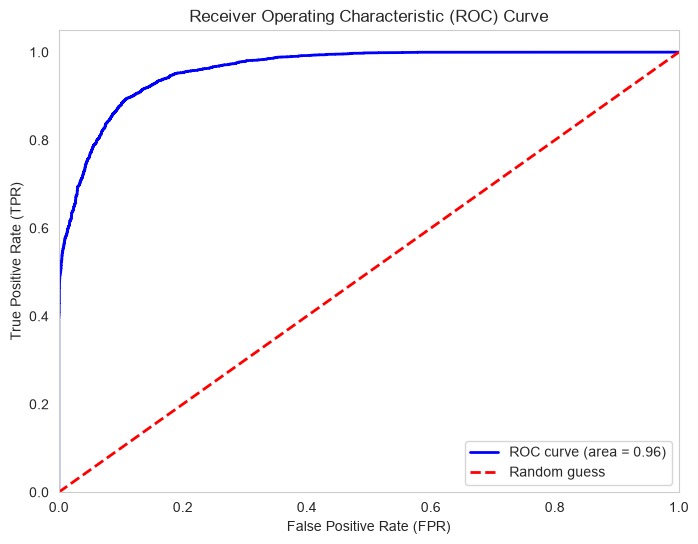

In [148]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt  

# Calculate the ROC curve
fpr, tpr, thresholds = roc_curve(y_val, logreg_pipeline.predict_proba(X_val)[:, 1])

# Calculate the AUC
roc_auc = roc_auc_score(y_val, logreg_pipeline.predict_proba(X_val)[:, 1])

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')  
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random guess')  
plt.xlim([0.0, 1.0])  
plt.ylim([0.0, 1.05])  
plt.xlabel('False Positive Rate (FPR)')  
plt.ylabel('True Positive Rate (TPR)')  
plt.title('Receiver Operating Characteristic (ROC) Curve')  
plt.legend(loc='lower right')  
plt.grid()  
plt.show()

In [149]:
from sklearn.neighbors import KNeighborsClassifier

# Create the pipeline with a KNN classifier
knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor), # Use the preprocessor pipeline defined earlier
    ('classifier', KNeighborsClassifier(n_neighbors=5)) # You can choose the number of neighbors (k) as desired
])

# Fit the pipeline to the training data
knn_pipeline.fit(X_train, y_train)

# Predict on the validation set
y_val_pred = knn_pipeline.predict(X_val)
y_val_pred_proba = knn_pipeline.predict_proba(X_val)[:, 1]

In [150]:
# Calculate and print the classification metrics for the KNN model
val_accuracy = accuracy_score(y_val, y_val_pred)
val_precision = precision_score(y_val, y_val_pred)
val_recall = recall_score(y_val, y_val_pred)
val_f1 = f1_score(y_val, y_val_pred)
val_roc_auc = roc_auc_score(y_val, y_val_pred_proba)

print("K-Nearest Neighbors (KNN) Metrics:")
print(f'Validation Accuracy: {val_accuracy:.5f}')
print(f'Validation Precision: {val_precision:.5f}')  
print(f'Validation Recall: {val_recall:.5f}')  
print(f'Validation F1 Score: {val_f1:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc:.5f}')

K-Nearest Neighbors (KNN) Metrics:
Validation Accuracy: 0.86455
Validation Precision: 0.87039
Validation Recall: 0.85462
Validation F1 Score: 0.86243
Validation ROC AUC: 0.93110


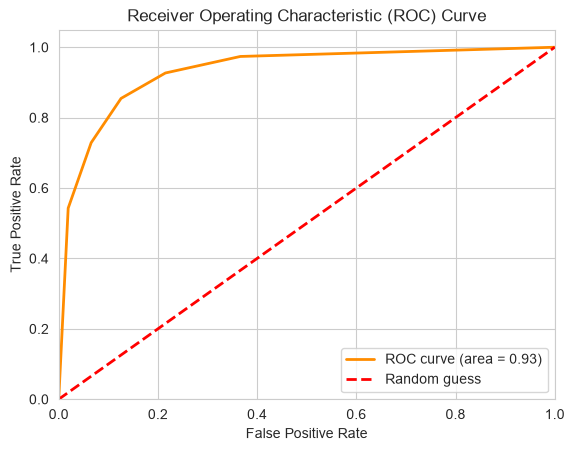

In [151]:
# Plot the ROC curve
fpr, tpr, thresholds = roc_curve(y_val, knn_pipeline.predict_proba(X_val)[:, 1])
roc_auc = roc_auc_score(y_val, knn_pipeline.predict_proba(X_val)[:, 1])

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')  
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random guess')  
plt.xlim([0.0, 1.0])  
plt.ylim([0.0, 1.05])  
plt.xlabel('False Positive Rate')  
plt.ylabel('True Positive Rate')  
plt.title('Receiver Operating Characteristic (ROC) Curve')  
plt.legend(loc="lower right")  
plt.grid(True)  
plt.show()

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Create the pipeline with a Decision Tree classifier
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(criterion='gini', min_samples_split=2, max_depth=None, random_state=42))  
])

# Fit the pipeline to the training data
dt_pipeline.fit(X_train, y_train)

# Predict on the validation set
y_val_pred = dt_pipeline.predict(X_val)
y_val_pred_proba = dt_pipeline.predict_proba(X_val)[:, 1]

# Calculate metrics for the validation set
val_accuracy = accuracy_score(y_val, y_val_pred)
val_precision = precision_score(y_val, y_val_pred)  
val_recall = recall_score(y_val, y_val_pred)  
val_f1 = f1_score(y_val, y_val_pred)  
val_roc_auc = roc_auc_score(y_val, y_val_pred_proba)  

# Calculate metrics for the training set
y_train_pred = dt_pipeline.predict(X_train)  
y_train_pred_proba = dt_pipeline.predict_proba(X_train)[:, 1]  

train_accuracy = accuracy_score(y_train, y_train_pred)  
train_precision = precision_score(y_train, y_train_pred)  
train_recall = recall_score(y_train, y_train_pred)  
train_f1 = f1_score(y_train, y_train_pred)  
train_roc_auc = roc_auc_score(y_train, y_train_pred_proba)  

print("Decision Tree Classifier Validation Metrics:")
print(f'Validation Accuracy: {val_accuracy:.5f}')
print(f'Validation Precision: {val_precision:.5f}')  
print(f'Validation Recall: {val_recall:.5f}')  
print(f'Validation F1 Score: {val_f1:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc:.5f}')  

print("\nTraining Set Metrics:")
print(f'Training Accuracy: {train_accuracy:.5f}')  
print(f'Training Precision: {train_precision:.5f}')  
print(f'Training Recall: {train_recall:.5f}')  
print(f'Training F1 Score: {train_f1:.5f}')  
print(f'Training ROC AUC: {train_roc_auc:.5f}')

Decision Tree Classifier Validation Metrics:
Validation Accuracy: 0.89226
Validation Precision: 0.89438
Validation Recall: 0.88799
Validation F1 Score: 0.89117
Validation ROC AUC: 0.89385
Training Set Metrics:
Training Accuracy: 0.99670
Training Precision: 0.99934
Training Recall: 0.99401
Training F1 Score: 0.99667
Training ROC AUC: 0.99998


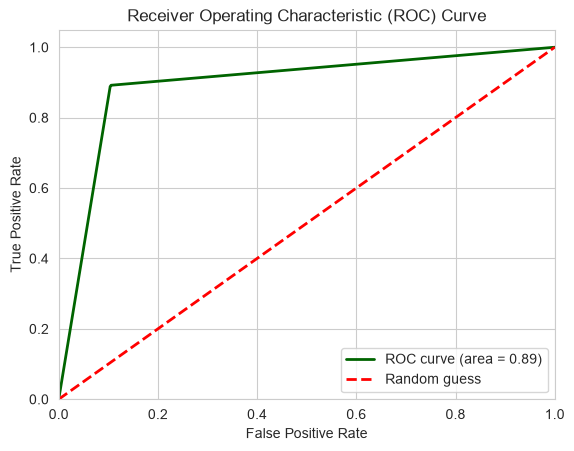

In [153]:
fpr, tpr, thresholds = roc_curve(y_val, y_val_pred_proba)
roc_auc = roc_auc_score(y_val, y_val_pred_proba)

plt.figure()  
plt.plot(fpr, tpr, color='darkgreen', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')  
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random guess')  
plt.xlim([0.0, 1.0])  
plt.ylim([0.0, 1.05])  
plt.xlabel('False Positive Rate')  
plt.ylabel('True Positive Rate')  
plt.title('Receiver Operating Characteristic (ROC) Curve')  
plt.legend(loc="lower right")  
plt.grid(True)  
plt.show()

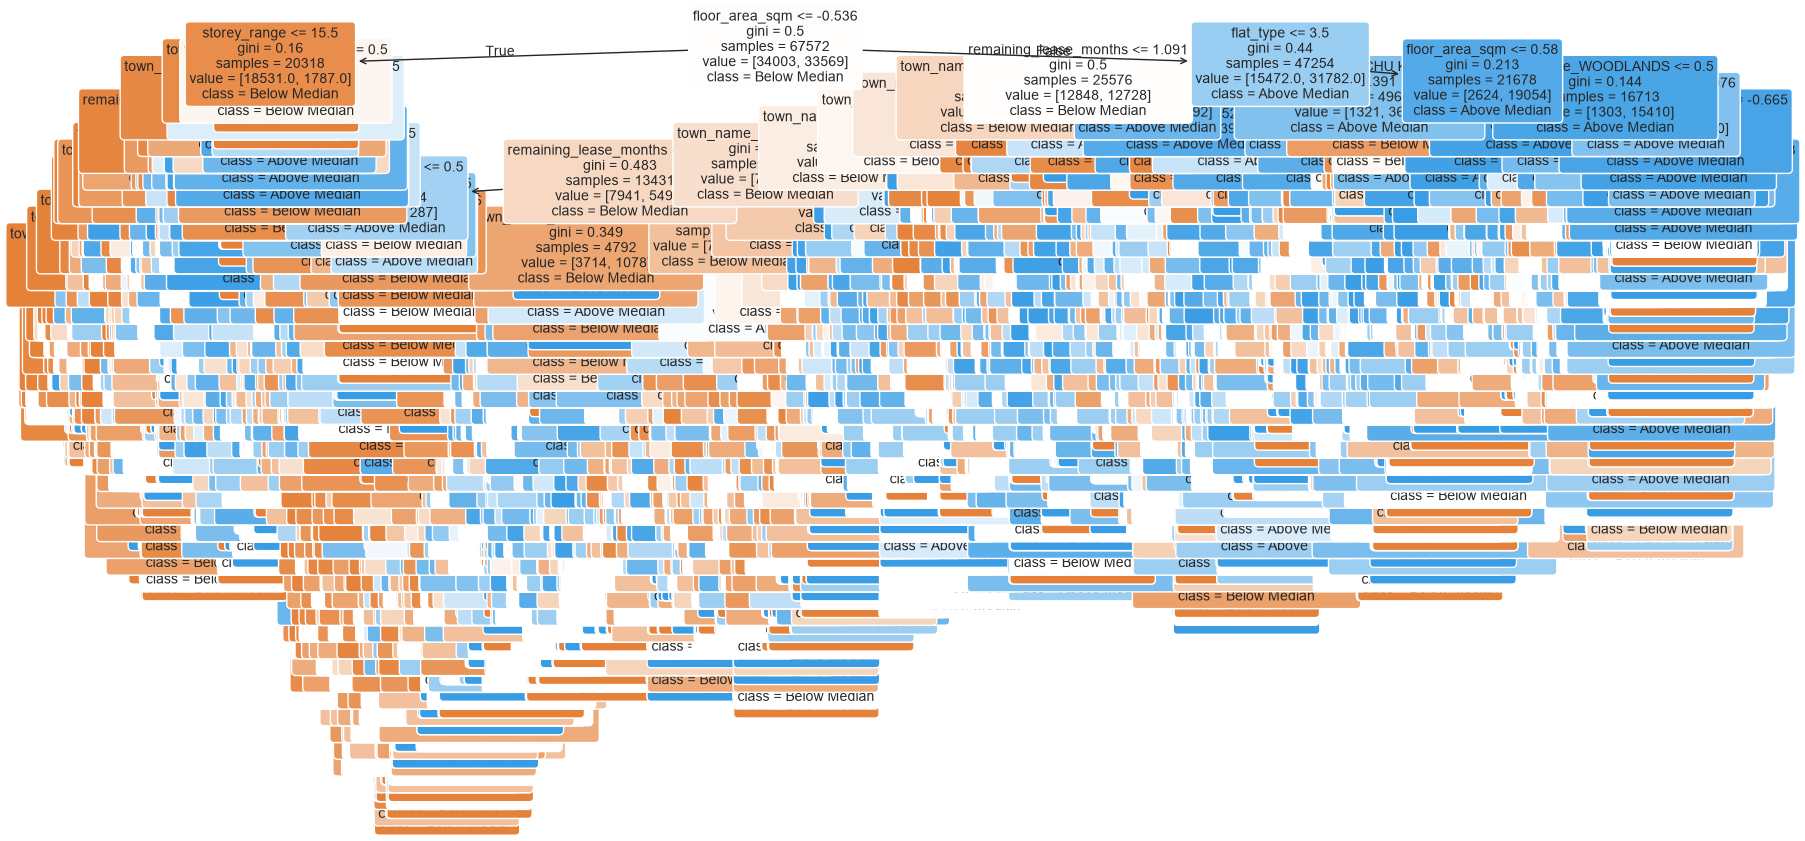

In [154]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Extract the transformed feature names
feature_names = []
for name, transformer, columns in dt_pipeline.named_steps['preprocessor'].transformers_:
    if hasattr(transformer, 'named_steps'):
        for step in transformer.named_steps.values():
            if hasattr(step, 'get_feature_names_out'):
                feature_names.extend(step.get_feature_names_out(columns))
    elif hasattr(transformer, 'get_feature_names_out'):
        feature_names.extend(transformer.get_feature_names_out(columns))
    else:
        feature_names.extend(columns)
				
# Plot the decision tree
plt.figure(figsize=(20, 10))
plot_tree(dt_pipeline.named_steps['classifier'], feature_names=feature_names, class_names=['Below Median', 'Above Median'], filled=True, rounded=True, fontsize=10)
plt.show()

In [ ]:
# Create the new pipeline with a Decision Tree classifier with new max_depth pre-pruning parameter
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(criterion='gini', min_samples_split=2, max_depth=5, min_samples_leaf=1, random_state=42))
])  

# Fit the pipeline to the training data
dt_pipeline.fit(X_train, y_train)

# Predict on the validation set
y_val_pred = dt_pipeline.predict(X_val)
y_val_pred_proba = dt_pipeline.predict_proba(X_val)[:, 1]

# Calculate metrics for the validation set
val_accuracy = accuracy_score(y_val, y_val_pred)
val_precision = precision_score(y_val, y_val_pred)  
val_recall = recall_score(y_val, y_val_pred)  
val_f1 = f1_score(y_val, y_val_pred)  
val_roc_auc = roc_auc_score(y_val, y_val_pred_proba)  

# Calculate metrics for the training set
y_train_pred = dt_pipeline.predict(X_train)  
y_train_pred_proba = dt_pipeline.predict_proba(X_train)[:, 1]  

train_accuracy = accuracy_score(y_train, y_train_pred)  
train_precision = precision_score(y_train, y_train_pred)  
train_recall = recall_score(y_train, y_train_pred)  
train_f1 = f1_score(y_train, y_train_pred)  
train_roc_auc = roc_auc_score(y_train, y_train_pred_proba)  

print("Decision Tree Classifier Validation Metrics:")
print(f'Validation Accuracy: {val_accuracy:.5f}')
print(f'Validation Precision: {val_precision:.5f}')  
print(f'Validation Recall: {val_recall:.5f}')  
print(f'Validation F1 Score: {val_f1:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc:.5f}')  

print("\nTraining Set Metrics:")
print(f'Training Accuracy: {train_accuracy:.5f}')  
print(f'Training Precision: {train_precision:.5f}')  
print(f'Training Recall: {train_recall:.5f}')  
print(f'Training F1 Score: {train_f1:.5f}')  
print(f'Training ROC AUC: {train_roc_auc:.5f}')

Decision Tree Classifier Validation Metrics:
Validation Accuracy: 0.81790
Validation Precision: 0.87820
Validation Recall: 0.73546
Validation F1 Score: 0.80052
Validation ROC AUC: 0.90754
Training Set Metrics:
Training Accuracy: 0.81270
Training Precision: 0.87365
Training Recall: 0.72832
Training F1 Score: 0.79439
Training ROC AUC: 0.90900


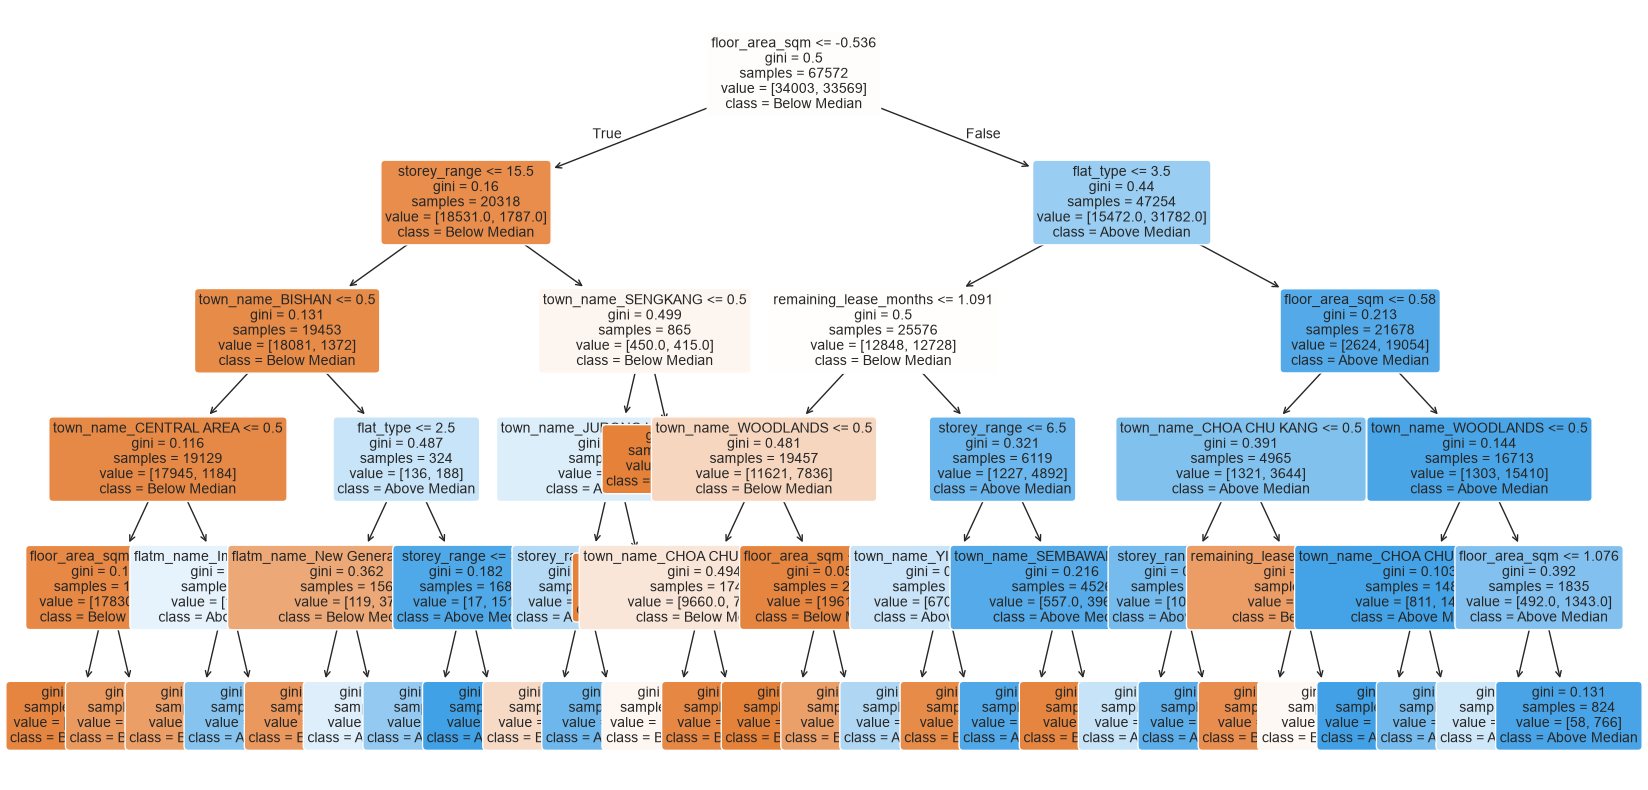

In [156]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Extract the transformed feature names
feature_names = []
for name, transformer, columns in dt_pipeline.named_steps['preprocessor'].transformers_:
    if hasattr(transformer, 'named_steps'):
        for step in transformer.named_steps.values():
            if hasattr(step, 'get_feature_names_out'):
                feature_names.extend(step.get_feature_names_out(columns))
    elif hasattr(transformer, 'get_feature_names_out'):
        feature_names.extend(transformer.get_feature_names_out(columns))
    else:
        feature_names.extend(columns)
				
# Plot the decision tree
plt.figure(figsize=(20, 10))
plot_tree(dt_pipeline.named_steps['classifier'], feature_names=feature_names, class_names=['Below Median', 'Above Median'], filled=True, rounded=True, fontsize=10)
plt.show()

In [157]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier

dt2_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

param_grid = {
    'classifier__criterion': ['gini', 'entropy', 'log_loss'],
    'classifier__max_depth': [3, 5, 7, 10, 15, None],
    'classifier__min_samples_split': [2, 5, 10, 20],
    'classifier__min_samples_leaf': [1, 2, 5, 10],
    'classifier__max_features': [None, 'sqrt', 'log2']
}

dt_random_search = RandomizedSearchCV(
    dt2_pipeline,
    param_distributions=param_grid,
    n_iter=10,
    cv=5,
    scoring='f1',
    random_state=42,
    n_jobs=-1
)

dt_random_search.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__criterion': ['gini', 'entropy', ...], 'classifier__max_depth': [3, 5, ...], 'classifier__max_features': [None, 'sqrt', ...], 'classifier__min_samples_leaf': [1, 2, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` dir

In [ ]:
# Best model from Decision Tree (Random Search)
best_dt_model = dt_random_search.best_estimator_

print("Best DT parameters:")
print(dt_random_search.best_params_)

print("\nBest DT cross-validation score:")
print(dt_random_search.best_score_)


Best DT parameters:
{'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 2, 'classifier__max_features': None, 'classifier__max_depth': 15, 'classifier__criterion': 'entropy'}

Best DT cross-validation score:
0.8897294989634084


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Best model from Decision Tree (Random Search)
best_dt_model = dt_random_search.best_estimator_

# Predict on the test set
y_val_pred_dt = best_dt_model.predict(X_val)
y_val_pred_proba_dt = best_dt_model.predict_proba(X_val)[:, 1]

# Calculate metrics for the validation set
val_accuracy_dt = accuracy_score(y_val, y_val_pred_dt)
val_precision_dt = precision_score(y_val, y_val_pred_dt)
val_recall_dt = recall_score(y_val, y_val_pred_dt)
val_f1_dt = f1_score(y_val, y_val_pred_dt)
val_roc_auc_dt = roc_auc_score(y_val, y_val_pred_proba_dt)

print("Decision Tree Tuned Validation Metrics:")
print(f'Validation Accuracy: {val_accuracy_dt:.5f}')
print(f'Validation Precision: {val_precision_dt:.5f}')  
print(f'Validation Recall: {val_recall_dt:.5f}')  
print(f'Validation F1 Score: {val_f1_dt:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc_dt:.5f}')  

print("\nDecision Tree Untuned Validation Metrics:")
print(f'Validation Accuracy: {val_accuracy:.5f}')
print(f'Validation Precision: {val_precision:.5f}')  
print(f'Validation Recall: {val_recall:.5f}')  
print(f'Validation F1 Score: {val_f1:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc:.5f}') 

print("\nTraining Set Untuned Metrics:")
print(f'Training Accuracy: {train_accuracy:.5f}')  
print(f'Training Precision: {train_precision:.5f}')  
print(f'Training Recall: {train_recall:.5f}')  
print(f'Training F1 Score: {train_f1:.5f}')  
print(f'Training ROC AUC: {train_roc_auc:.5f}')


Decision Tree Tuned Validation Metrics:
Validation Accuracy: 0.88811
Validation Precision: 0.91626
Validation Recall: 0.85272
Validation F1 Score: 0.88335
Validation ROC AUC: 0.94670

Decision Tree Untuned Validation Metrics:
Validation Accuracy: 0.81790
Validation Precision: 0.87820
Validation Recall: 0.73546
Validation F1 Score: 0.80052
Validation ROC AUC: 0.90754

Training Set Metrics:
Training Accuracy: 0.81270
Training Precision: 0.87365
Training Recall: 0.72832
Training F1 Score: 0.79439
Training ROC AUC: 0.90900


In [163]:
# Confusion matrix and detailed report
val_confusion_matrix_dt = confusion_matrix(y_val, y_val_pred_dt)
val_classification_report_dt = classification_report(y_val, y_val_pred_dt)

print("\nDecision Tree Tuned Validation Confusion Matrix:")
print(val_confusion_matrix_dt)

print("\nDecision Tree Tuned Validation Classification Report:")
print(val_classification_report_dt)


Decision Tree Tuned Validation Confusion Matrix:
[[3923  327]
 [ 618 3578]]

Decision Tree Tuned Validation Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.92      0.89      4250
           1       0.92      0.85      0.88      4196

    accuracy                           0.89      8446
   macro avg       0.89      0.89      0.89      8446
weighted avg       0.89      0.89      0.89      8446



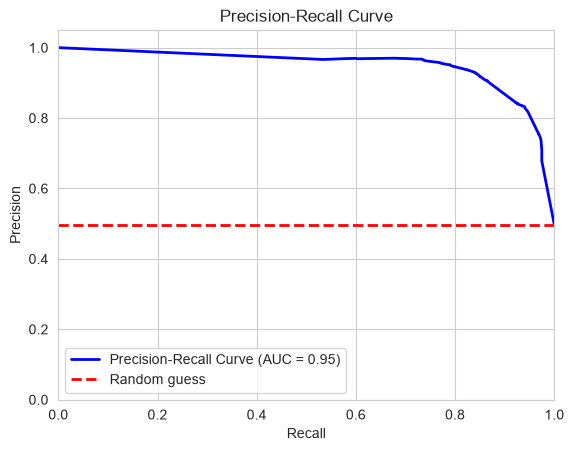

In [164]:
from sklearn.metrics import precision_recall_curve, auc
import matplotlib.pyplot as plt
import numpy as np

# Get the tuned decision-tree model
best_dt_model = dt_random_search.best_estimator_

# Get predicted probabilities for the positive class
y_val_pred_proba_dt = best_dt_model.predict_proba(X_val)[:, 1]

# Calculate precision, recall, and thresholds
precision_dt, recall_dt, thresholds_dt = precision_recall_curve(y_val, y_val_pred_proba_dt)

# Calculate the area under the precision-recall curve
pr_auc_dt = auc(recall_dt, precision_dt)

# Plot the Precision-Recall curve
plt.figure()
plt.plot(
    recall_dt,
    precision_dt,
    color='blue',
    lw=2,
    label=f'Precision-Recall Curve (AUC = {pr_auc_dt:.2f})'
)

# Plot the random-guess baseline, as horizontal line
plt.plot(
    [0, 1],
    [np.mean(y_val), np.mean(y_val)],
    color='red',
    lw=2,
    linestyle='--',
    label='Random guess'
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()